In [46]:
# check the directory path 
from pathlib import Path

dataset_path = Path(r"D:\Hope\AI in Tamil\Python\AI Deep Learning\Event Crowd Analysis\ShanghaiTech\part_B")

print(dataset_path)
print(dataset_path.exists())

D:\Hope\AI in Tamil\Python\AI Deep Learning\Event Crowd Analysis\ShanghaiTech\part_B
True


In [47]:
# Check the train data images numbers
image_folder = dataset_path / "train_data" / "images"
gt_folder = dataset_path / "train_data" / "ground-truth"

print("Image folder exists:", image_folder.exists())
print("Ground-truth folder exists:", gt_folder.exists())

images = sorted(image_folder.glob("*.jpg"))
mat_files = sorted(gt_folder.glob("*.mat"))

print("Images:", len(images))
print("MAT files:", len(mat_files))

Image folder exists: True
Ground-truth folder exists: True
Images: 400
MAT files: 400


In [48]:
# Check the first 5 images 
print("\nFirst 5 images:")
for f in images[:5]:
    print(f.name)

print("\nFirst 5 MAT files:")
for f in mat_files[:5]:
    print(f.name)


First 5 images:
processed_IMG_1.jpg
processed_IMG_10.jpg
processed_IMG_100.jpg
processed_IMG_101.jpg
processed_IMG_102.jpg

First 5 MAT files:
GT_IMG_1.mat
GT_IMG_10.mat
GT_IMG_100.mat
GT_IMG_101.mat
GT_IMG_102.mat


In [49]:
import shutil
from pathlib import Path

# Project folders
project_path = Path(r"D:\Crowd_Analysis_CSRNet")

train_img_dest = project_path / "dataset" / "train" / "images"
train_gt_dest = project_path / "dataset" / "train" / "ground_truth"

val_img_dest = project_path / "dataset" / "val" / "images"
val_gt_dest = project_path / "dataset" / "val" / "ground_truth"

# Create folders
for folder in [train_img_dest, train_gt_dest,
               val_img_dest, val_gt_dest]:
    folder.mkdir(parents=True, exist_ok=True)

# Select first 100 images
selected_images = images[:100]

# 80 train + 20 validation
train_images = selected_images[:80]
val_images = selected_images[80:100]

print("Training images:", len(train_images))
print("Validation images:", len(val_images))

Training images: 80
Validation images: 20


In [50]:
#Copy the images and matching .mat files

for img_path in train_images:

    # Copy image
    shutil.copy2(
        img_path,
        train_img_dest / img_path.name
    )

    # Matching ground truth
    gt_name = "GT_" + img_path.stem + ".mat"
    gt_path = gt_folder / gt_name

    shutil.copy2(
        gt_path,
        train_gt_dest / gt_name
    )


for img_path in val_images:

    # Copy image
    shutil.copy2(
        img_path,
        val_img_dest / img_path.name
    )

    # Matching ground truth
    gt_name = "GT_" + img_path.stem + ".mat"
    gt_path = gt_folder / gt_name

    shutil.copy2(
        gt_path,
        val_gt_dest / gt_name
    )

print("Dataset copying completed!")

FileNotFoundError: [Errno 2] No such file or directory: 'D:\\Hope\\AI in Tamil\\Python\\AI Deep Learning\\Event Crowd Analysis\\ShanghaiTech\\part_B\\train_data\\ground-truth\\GT_processed_IMG_1.mat'

In [51]:
print("Image filenames:")
for f in images[:10]:
    print(f.name)

print("\nGround-truth filenames:")
for f in sorted(gt_folder.glob("*.mat"))[:10]:
    print(f.name)

Image filenames:
processed_IMG_1.jpg
processed_IMG_10.jpg
processed_IMG_100.jpg
processed_IMG_101.jpg
processed_IMG_102.jpg
processed_IMG_103.jpg
processed_IMG_104.jpg
processed_IMG_105.jpg
processed_IMG_106.jpg
processed_IMG_107.jpg

Ground-truth filenames:
GT_IMG_1.mat
GT_IMG_10.mat
GT_IMG_100.mat
GT_IMG_101.mat
GT_IMG_102.mat
GT_IMG_103.mat
GT_IMG_104.mat
GT_IMG_105.mat
GT_IMG_106.mat
GT_IMG_107.mat


In [52]:
import shutil

def copy_image_and_gt(img_path, img_dest, gt_dest):
    # Remove "processed_" from the image filename
    original_stem = img_path.stem.replace("processed_", "", 1)

    # Find matching ground-truth file
    gt_name = "GT_" + original_stem + ".mat"
    gt_path = gt_folder / gt_name

    if not gt_path.exists():
        print("Missing ground truth:", gt_name)
        return False

    shutil.copy2(img_path, img_dest / img_path.name)
    shutil.copy2(gt_path, gt_dest / gt_name)
    return True


# Copy training images and ground truth
train_success = sum(
    copy_image_and_gt(img, train_img_dest, train_gt_dest)
    for img in train_images
)

# Copy validation images and ground truth
val_success = sum(
    copy_image_and_gt(img, val_img_dest, val_gt_dest)
    for img in val_images
)

print("\nCopying completed!")
print("Training pairs copied:", train_success)
print("Validation pairs copied:", val_success)



Copying completed!
Training pairs copied: 80
Validation pairs copied: 20


In [53]:
print("TRAIN")
print("Images:", len(list(train_img_dest.glob("*.jpg"))))
print("MAT files:", len(list(train_gt_dest.glob("*.mat"))))

print("\nVALIDATION")
print("Images:", len(list(val_img_dest.glob("*.jpg"))))
print("MAT files:", len(list(val_gt_dest.glob("*.mat"))))


TRAIN
Images: 80
MAT files: 80

VALIDATION
Images: 20
MAT files: 20


In [54]:
# Load one ground-truth file

import scipy.io as sio
import numpy as np

# Select one training ground-truth file
mat_path = train_gt_dest / "GT_IMG_1.mat"

data = sio.loadmat(str(mat_path))

print("MAT keys:", data.keys())


MAT keys: dict_keys(['__header__', '__version__', '__globals__', 'image_info'])


In [55]:
# Inspect the annotation structure
print(data["image_info"])
print("Shape:", data["image_info"].shape)
print("Data type:", data["image_info"].dtype)

[[array([[(array([[  32.67954877,  753.52165403],
                 [ 184.60695349,  690.79933098],
                 [ 344.89733461,  577.8991495 ],
                 [ 328.1713818 ,  536.08426746],
                 [ 329.5652112 ,  473.36194441],
                 [ 643.17682645,  533.29660866],
                 [ 661.29660866,  681.04252518],
                 [ 803.46720757,  580.6868083 ],
                 [ 814.61784278,  502.63236184],
                 [ 757.47083734,  392.51983915],
                 [ 770.01530195,  364.64325113],
                 [ 799.28571937,  315.85922209],
                 [ 728.20041991,  328.4036867 ],
                 [ 899.64143625,  405.06430376],
                 [ 919.15504786,  529.11512046],
                 [ 924.73036547,  278.22582826],
                 [ 965.1514181 ,  250.34924024],
                 [1018.11693534,  236.41094623],
                 [ 938.66865948,  186.23308779],
                 [ 896.85377745,  168.11330558],
                 [ 

In [56]:
# Extract the head coordinates

image_info = data["image_info"]

points = image_info[0, 0]["location"][0, 0]

print("Head-point array shape:", points.shape)
print("First 5 head points:")
print(points[:5])

print("Actual crowd count:", len(points))


Head-point array shape: (233, 2)
First 5 head points:
[[ 32.67954877 753.52165403]
 [184.60695349 690.79933098]
 [344.89733461 577.8991495 ]
 [328.1713818  536.08426746]
 [329.5652112  473.36194441]]
Actual crowd count: 233


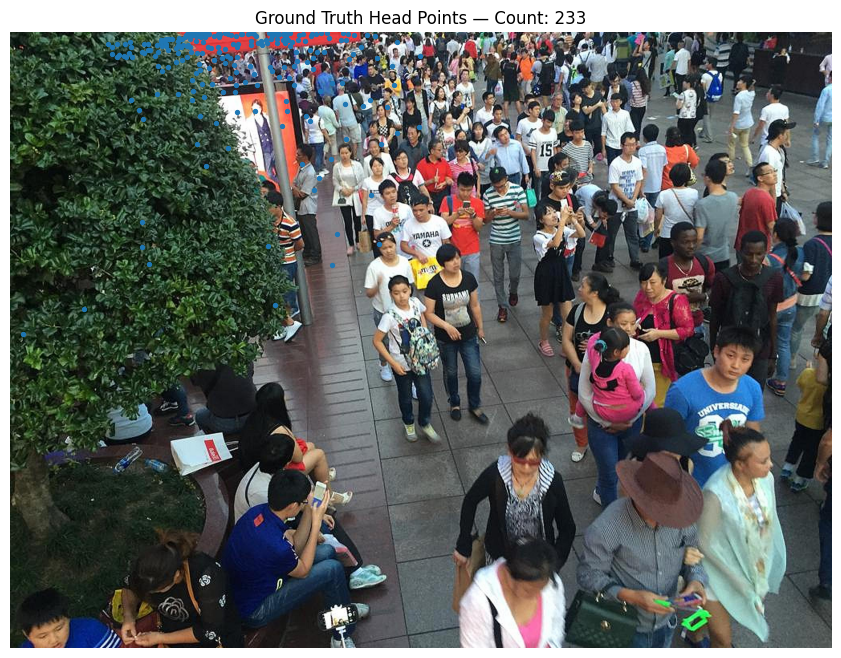

In [57]:
# Display the image with head points

import matplotlib.pyplot as plt
import cv2

img_path = train_img_dest / "processed_IMG_1.jpg"

image = cv2.imread(str(img_path))
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(image_rgb)
plt.scatter(points[:, 0], points[:, 1], s=8)
plt.title(f"Ground Truth Head Points — Count: {len(points)}")
plt.axis("off")
plt.show()


In [58]:
# Generate the density map

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# Get image dimensions
height, width = image_rgb.shape[:2]

# Create an empty map
point_map = np.zeros((height, width), dtype=np.float32)

# Add one point for each annotated head
for x, y in points:
    x = int(round(x))
    y = int(round(y))

    if 0 <= x < width and 0 <= y < height:
        point_map[y, x] += 1

# Smooth head points into a density map
density_map = gaussian_filter(point_map, sigma=4)

# Normalize so the density map sums to the annotated count
if density_map.sum() > 0:
    density_map *= point_map.sum() / density_map.sum()

print("Annotated people:", int(point_map.sum()))
print("Density map total:", round(float(density_map.sum()), 2))
print("Density map shape:", density_map.shape)

# This uses Gaussian smoothing to turn individual head points into a continuous density map, a standard preprocessing approach for CSRNet

Annotated people: 233
Density map total: 233.0
Density map shape: (1536, 2048)


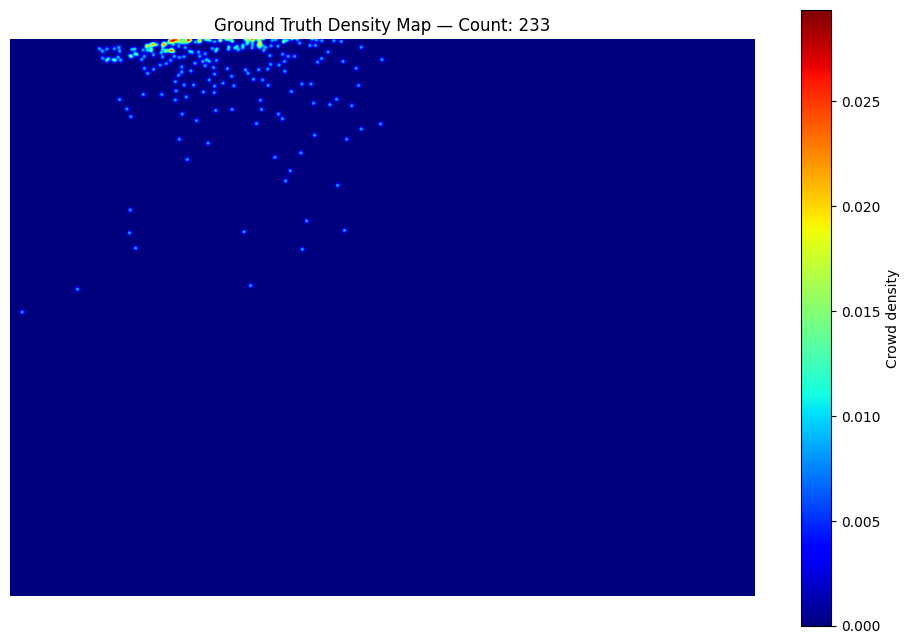

In [59]:
# Visualize the density map

plt.figure(figsize=(12, 8))

plt.imshow(density_map, cmap="jet")
plt.colorbar(label="Crowd density")
plt.title(f"Ground Truth Density Map — Count: {int(point_map.sum())}")
plt.axis("off")

plt.show()


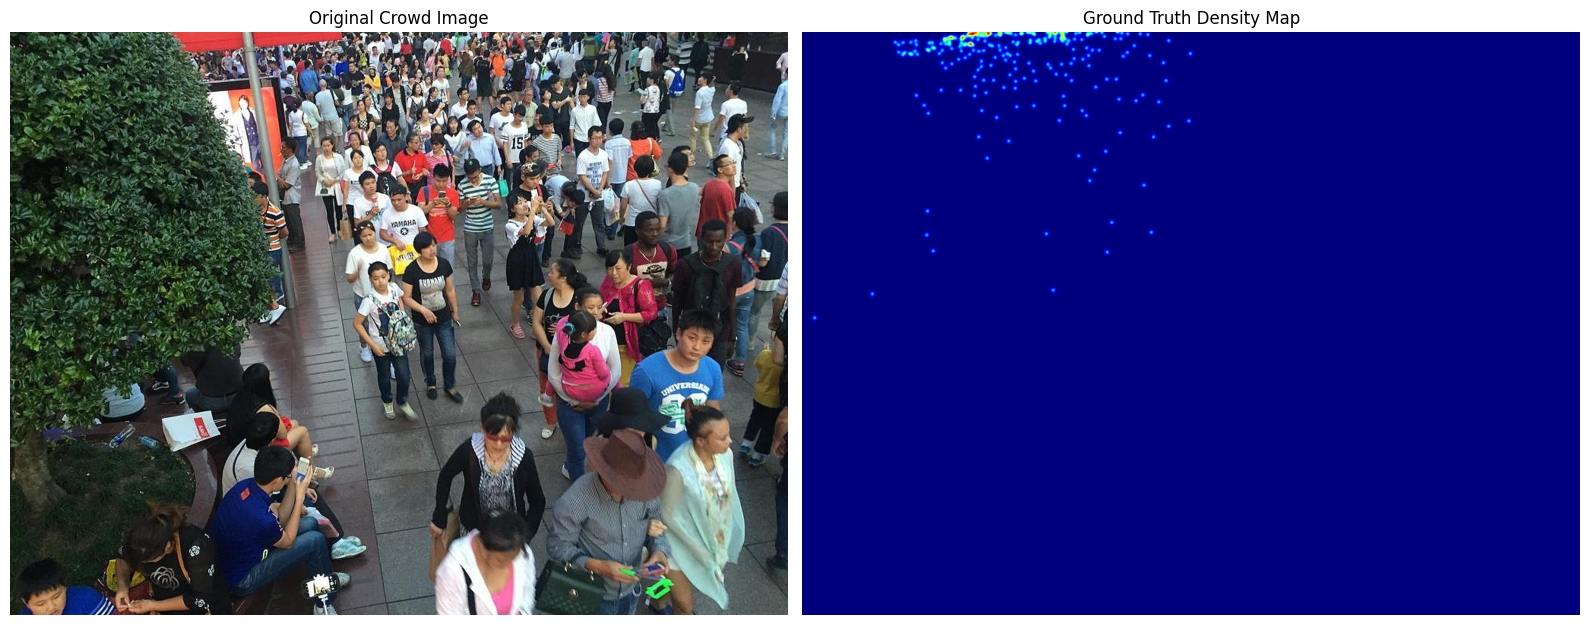

Actual crowd count: 233
Density map sum: 233.0


In [60]:
# Compare the original image and density map

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(image_rgb)
axes[0].set_title("Original Crowd Image")
axes[0].axis("off")

axes[1].imshow(density_map, cmap="jet")
axes[1].set_title("Ground Truth Density Map")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Actual crowd count:", int(point_map.sum()))
print("Density map sum:", round(float(density_map.sum()), 2))


In [61]:
# Generate density maps for all 100 images
# Create a folder for density maps
from pathlib import Path

train_density_dir = Path("density_maps/train")
val_density_dir = Path("density_maps/val")

train_density_dir.mkdir(parents=True, exist_ok=True)
val_density_dir.mkdir(parents=True, exist_ok=True)

print("Training density folder:", train_density_dir.resolve())
print("Validation density folder:", val_density_dir.resolve())

Training density folder: D:\Hope\AI in Tamil\Python\AI Deep Learning\Event Crowd Analysis\density_maps\train
Validation density folder: D:\Hope\AI in Tamil\Python\AI Deep Learning\Event Crowd Analysis\density_maps\val


In [62]:
# Generate density maps and save them

import numpy as np
import scipy.io as sio
from PIL import Image
from scipy.ndimage import gaussian_filter
from pathlib import Path
from tqdm import tqdm

# Original dataset folders
dataset_path = Path(
    r"D:\Hope\AI in Tamil\Python\AI Deep Learning\Event Crowd Analysis\ShanghaiTech\part_B"
)

image_dir = dataset_path / "train_data" / "images"
gt_dir = dataset_path / "train_data" / "ground-truth"

def create_density_map(image_path, gt_path, save_path):
    # Read image dimensions
    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    # Read head-point annotations
    mat_data = sio.loadmat(str(gt_path))
    points = mat_data["image_info"][0, 0]["location"][0, 0]

    # Create a point map
    point_map = np.zeros((height, width), dtype=np.float32)

    for x, y in points:
        x, y = int(round(x)), int(round(y))

        if 0 <= x < width and 0 <= y < height:
            point_map[y, x] += 1

    # Smooth head points into a density map
    density_map = gaussian_filter(point_map, sigma=4)

    # Preserve the annotated crowd count
    if density_map.sum() > 0:
        density_map *= point_map.sum() / density_map.sum()

    # Save as a NumPy file
    np.save(save_path, density_map)

    return int(point_map.sum())


# Process your selected 100 images
processed = 0
failed = []

for image_path in tqdm(sorted(image_dir.glob("processed_*.jpg"))):
    original_stem = image_path.stem.replace("processed_", "", 1)
    gt_path = gt_dir / f"GT_{original_stem}.mat"

    if not gt_path.exists():
        continue

    # Only process images copied into your 80/20 split
    train_file = train_img_dest / image_path.name
    val_file = val_img_dest / image_path.name

    if train_file.exists():
        save_path = train_density_dir / f"{image_path.stem}.npy"
    elif val_file.exists():
        save_path = val_density_dir / f"{image_path.stem}.npy"
    else:
        continue

    try:
        count = create_density_map(image_path, gt_path, save_path)
        processed += 1
    except Exception as e:
        failed.append((image_path.name, str(e)))

print("Density maps created:", processed)
print("Failed files:", len(failed))

if failed:
    print("First errors:", failed[:3])

100%|██████████| 400/400 [00:33<00:00, 11.89it/s]

Density maps created: 100
Failed files: 0


File: processed_IMG_1.npy
Density map shape: (1536, 2048)
Estimated crowd count: 233.0


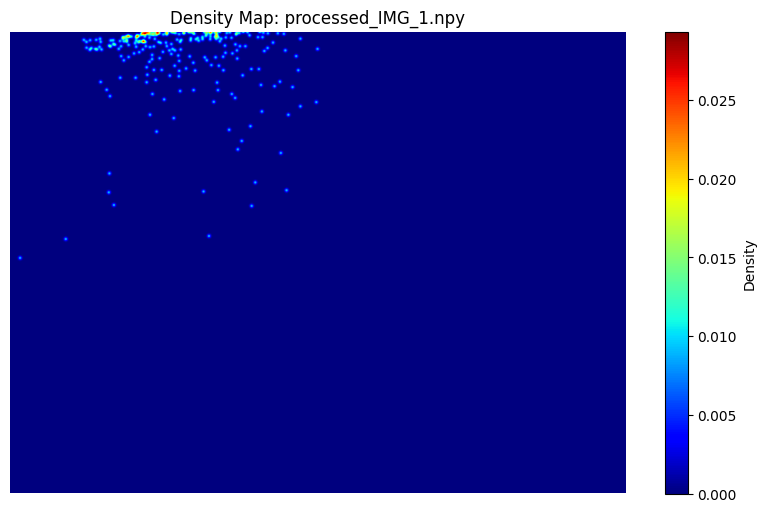

In [63]:
# Check the saved density maps
import matplotlib.pyplot as plt
import numpy as np

density_file = next(train_density_dir.glob("*.npy"))
density_map = np.load(density_file)

print("File:", density_file.name)
print("Density map shape:", density_map.shape)
print("Estimated crowd count:", round(float(density_map.sum()), 2))

plt.figure(figsize=(10, 6))
plt.imshow(density_map, cmap="jet")
plt.colorbar(label="Density")
plt.title(f"Density Map: {density_file.name}")
plt.axis("off")
plt.show()

In [64]:
# Build the PyTorch Dataset and DataLoader
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
from pathlib import Path

In [65]:
# Create the dataset class
# The original images are large, so resize each image to a smaller size for initial CPU-based experiments. resize the density map consistently and preserve its total count

class CrowdDataset(Dataset):

    def __init__(self, image_dir, density_dir, size=(512, 384)):
        self.image_dir = Path(image_dir)
        self.density_dir = Path(density_dir)
        self.size = size  # (width, height)

        self.image_files = sorted(self.image_dir.glob("processed_*.jpg"))

        self.samples = []
        for image_path in self.image_files:
            density_path = self.density_dir / f"{image_path.stem}.npy"
            if density_path.exists():
                self.samples.append((image_path, density_path))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, density_path = self.samples[index]

        # Load and resize image
        image = Image.open(image_path).convert("RGB")
        image = image.resize(self.size, Image.Resampling.BILINEAR)

        image = np.asarray(image, dtype=np.float32) / 255.0
        image = torch.from_numpy(image).permute(2, 0, 1)

        # Load density map
        density = np.load(density_path).astype(np.float32)
        original_count = float(density.sum())
        
        density_image = Image.fromarray(density)
        density_image = density_image.resize(
            self.size, Image.Resampling.BILINEAR
        )
    
    # Create a writable NumPy array
        density = np.array(
            density_image,
            dtype=np.float32,
            copy=True
        )
    
    # Preserve the original crowd count
        if density.sum() > 0:
            density *= original_count / density.sum()
        
        density = torch.from_numpy(density).unsqueeze(0)
        
        return image, density

In [66]:
# Create training and validation DataLoaders
train_dataset = CrowdDataset(
    train_img_dest,
    train_density_dir
)

val_dataset = CrowdDataset(
    val_img_dest,
    val_density_dir
)

train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 80
Validation images: 20


In [67]:
# Test one batch

images, density_maps = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Density batch shape:", density_maps.shape)
print("Ground-truth count:", density_maps.sum().item())

Image batch shape: torch.Size([1, 3, 384, 512])
Density batch shape: torch.Size([1, 1, 384, 512])
Ground-truth count: 100.0


In [68]:
# Build the CSRNet architecture
# CSRNet uses two main components:
# 1. Frontend: extracts image features using convolutional layers.
# 2. Backend: uses dilated convolutions to estimate the crowd-density map.
# Define the model

import torch
import torch.nn as nn


class CSRNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Frontend: feature extraction
        self.frontend = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        # Backend: dilated convolutions
        self.backend = nn.Sequential(
            nn.Conv2d(256, 256, kernel_size=3, padding=2, dilation=2),
            nn.ReLU(inplace=True),

            nn.Conv2d(256, 128, kernel_size=3, padding=2, dilation=2),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 64, kernel_size=3, padding=2, dilation=2),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 1, kernel_size=1),
            nn.ReLU(inplace=True)
        ) 

    def forward(self, x):
        x = self.frontend(x)
        x = self.backend(x)
        return x
    

In [93]:
model = CSRNet().to(device)

images, density_maps = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    predictions = model(images)

print("Input image shape:", images.shape)
print("Model output shape:", predictions.shape)
print("Predicted crowd count:", predictions.sum().item())



Input image shape: torch.Size([1, 3, 384, 512])
Model output shape: torch.Size([1, 1, 48, 64])
Predicted crowd count: 75.29266357421875


In [94]:
# Prepare matching density-map targets

import torch.nn.functional as F

density_maps = density_maps.to(device)

target_small = F.interpolate(
    density_maps,
    size=predictions.shape[-2:],
    mode="bilinear",
    align_corners=False
)

# Preserve the original crowd count after resizing
original_counts = density_maps.sum(dim=(2, 3), keepdim=True)
resized_counts = target_small.sum(dim=(2, 3), keepdim=True)

target_small = target_small * (
    original_counts / resized_counts.clamp_min(1e-8)
)

print("Target shape:", target_small.shape)
print("Target count:", target_small.sum().item())

Target shape: torch.Size([1, 1, 48, 64])
Target count: 43.0


In [95]:
# Check the original and resized counts
print("Original density count:",
      density_maps.sum().item())

print("Resized target count:",
      target_small.sum().item())

print("Difference:",
      abs(density_maps.sum().item() -
          target_small.sum().item()))

Original density count: 43.0
Resized target count: 43.0
Difference: 0.0


In [97]:
# Train the model
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cpu")
model = model.to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-5
)

epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, density_maps in train_loader:
        images = images.to(device)
        density_maps = density_maps.to(device)

        optimizer.zero_grad()

        predictions = model(images)

        # Resize density targets to model output dimensions
        targets = F.interpolate(
            density_maps,
            size=predictions.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Preserve the total crowd count
        original_counts = density_maps.sum(
            dim=(2, 3), keepdim=True
        )
        resized_counts = targets.sum(
            dim=(2, 3), keepdim=True
        )

        targets = targets * (
            original_counts / resized_counts.clamp_min(1e-8)
        )

        loss = criterion(predictions, targets)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{epochs}], "
        f"Training Loss: {avg_loss:.6f}"
    )

Epoch [1/5], Training Loss: 0.230381
Epoch [2/5], Training Loss: 0.230227
Epoch [3/5], Training Loss: 0.230061
Epoch [4/5], Training Loss: 0.229823
Epoch [5/5], Training Loss: 0.229534


In [98]:
# Save trained model
import torch
from pathlib import Path

model_path = Path("csrnet_crowd_model.pth")

torch.save(model.state_dict(), model_path)

print("Model saved successfully!")
print("Saved location:", model_path.resolve())

Model saved successfully!
Saved location: D:\Hope\AI in Tamil\Python\AI Deep Learning\Event Crowd Analysis\csrnet_crowd_model.pth


In [99]:
# Evaluate the model on validation images
# compare the predicted crowd counts with the actual annotated counts for 20 validation images
import torch
import torch.nn.functional as F
import numpy as np

device = torch.device("cpu")
model = model.to(device)
model.eval()

actual_counts = []
predicted_counts = []

with torch.no_grad():
    for images, density_maps in val_loader:
        images = images.to(device)

        # Predict the density map
        predictions = model(images)

        # Ground-truth count from the original density map
        actual_count = density_maps.sum().item()

        # Predicted count from the model output
        predicted_count = predictions.sum().item()

        actual_counts.append(actual_count)
        predicted_counts.append(predicted_count)

print("Validation images evaluated:", len(actual_counts))

for i, (actual, predicted) in enumerate(
    zip(actual_counts, predicted_counts), start=1
):
    print(
        f"Image {i}: Actual = {actual:.0f}, "
        f"Predicted = {predicted:.2f}"
    )

Validation images evaluated: 20
Image 1: Actual = 15, Predicted = 96.43
Image 2: Actual = 142, Predicted = 125.37
Image 3: Actual = 42, Predicted = 109.53
Image 4: Actual = 173, Predicted = 133.34
Image 5: Actual = 378, Predicted = 118.71
Image 6: Actual = 281, Predicted = 124.58
Image 7: Actual = 96, Predicted = 105.45
Image 8: Actual = 61, Predicted = 105.56
Image 9: Actual = 45, Predicted = 97.94
Image 10: Actual = 178, Predicted = 98.13
Image 11: Actual = 65, Predicted = 111.79
Image 12: Actual = 108, Predicted = 139.51
Image 13: Actual = 105, Predicted = 109.77
Image 14: Actual = 116, Predicted = 102.84
Image 15: Actual = 81, Predicted = 113.96
Image 16: Actual = 136, Predicted = 122.82
Image 17: Actual = 208, Predicted = 120.45
Image 18: Actual = 125, Predicted = 132.85
Image 19: Actual = 344, Predicted = 132.68
Image 20: Actual = 90, Predicted = 125.66


In [102]:
# Calculate the crowd-counting error
actual = np.array(actual_counts)
predicted = np.array(predicted_counts)

mae = np.mean(np.abs(predicted - actual))
rmse = np.sqrt(np.mean((predicted - actual) ** 2))

print(f"Mean Absolute Error (MAE): {mae:.2f} people")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} people")

Mean Absolute Error (MAE): 64.63 people
Root Mean Squared Error (RMSE): 93.35 people


In [103]:
# average, the predicted crowd count differs from the actual count by about 82 people. The RMSE indicates that some predictions may have larger errors.
#MAE: the average absolute difference between predicted and actual crowd counts.
#RMSE: a measure that penalizes large counting errors more heavily.

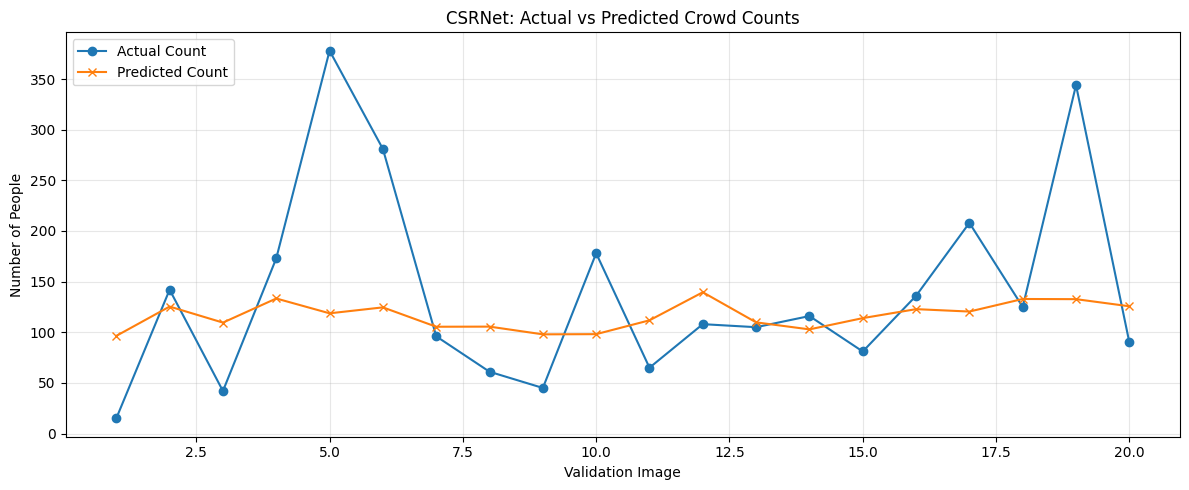

Mean actual count: 139.45
Mean predicted count: 116.37
Average signed error: -23.08


In [104]:
# Inspect actual versus predicted counts
import matplotlib.pyplot as plt
import numpy as np

actual = np.array(actual_counts)
predicted = np.array(predicted_counts)

plt.figure(figsize=(12, 5))

plt.plot(
    range(1, len(actual) + 1),
    actual,
    marker="o",
    label="Actual Count"
)

plt.plot(
    range(1, len(predicted) + 1),
    predicted,
    marker="x",
    label="Predicted Count"
)

plt.xlabel("Validation Image")
plt.ylabel("Number of People")
plt.title("CSRNet: Actual vs Predicted Crowd Counts")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Mean actual count:", round(actual.mean(), 2))
print("Mean predicted count:", round(predicted.mean(), 2))
print("Average signed error:", round((predicted - actual).mean(), 2))

In [105]:
# Check for negative density predictions
print("Minimum predicted density:", predictions.min().item())
print("Maximum predicted density:", predictions.max().item())

Minimum predicted density: 0.0
Maximum predicted density: 0.5289032459259033


In [106]:
# Output : Evaluate crowd-counting performance
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
actual = np.array(actual_counts, dtype=float)
predicted = np.array(predicted_counts, dtype=float)

mae = np.mean(np.abs(predicted - actual))
rmse = np.sqrt(np.mean((predicted - actual) ** 2))
bias = np.mean(predicted - actual)

results = pd.DataFrame({
    "Metric": [
        "Validation Images",
        "Mean Actual Crowd Count",
        "Mean Predicted Crowd Count",
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "Average Signed Error"
    ],
    "Value": [
        len(actual),
        round(actual.mean(), 2),
        round(predicted.mean(), 2),
        round(mae, 2),
        round(rmse, 2),
        round(bias, 2)
    ]
})

print("EVENT CROWD ANALYSIS - FINAL EVALUATION")
print(results.to_string(index=False))

EVENT CROWD ANALYSIS - FINAL EVALUATION
                        Metric  Value
             Validation Images  20.00
       Mean Actual Crowd Count 139.45
    Mean Predicted Crowd Count 116.37
     Mean Absolute Error (MAE)  64.63
Root Mean Squared Error (RMSE)  93.35
          Average Signed Error -23.08


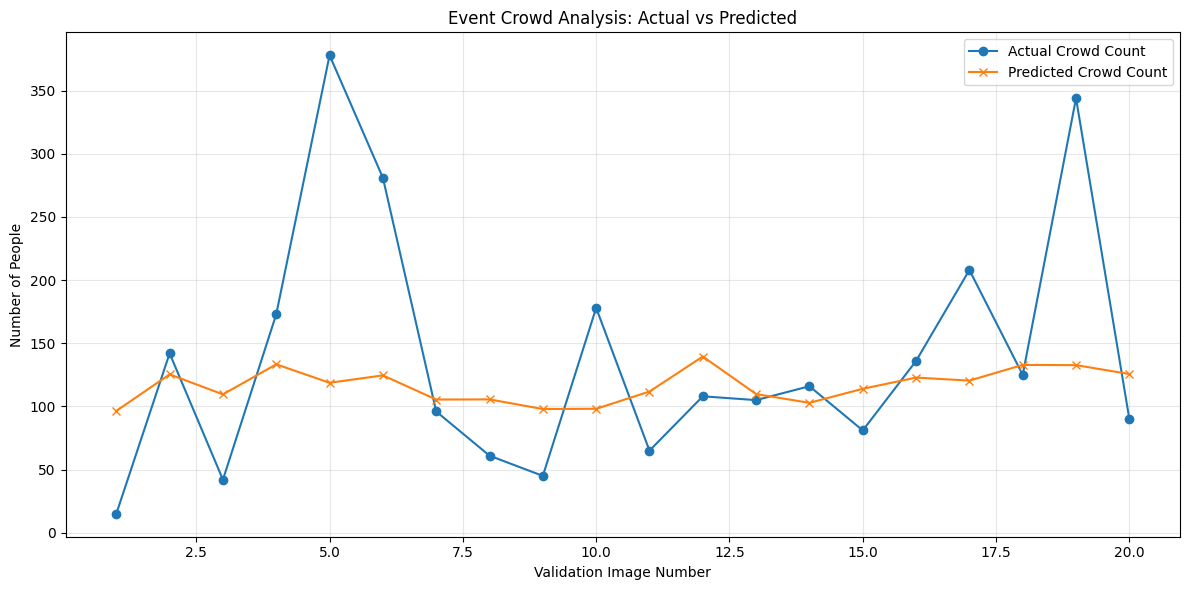

In [107]:
# Output 2: Compare actual and predicted crowd counts

plt.figure(figsize=(12, 6))

image_numbers = np.arange(1, len(actual) + 1)

plt.plot(
    image_numbers, actual,
    marker="o", label="Actual Crowd Count"
)

plt.plot(
    image_numbers, predicted,
    marker="x", label="Predicted Crowd Count"
)

plt.xlabel("Validation Image Number")
plt.ylabel("Number of People")
plt.title("Event Crowd Analysis: Actual vs Predicted")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


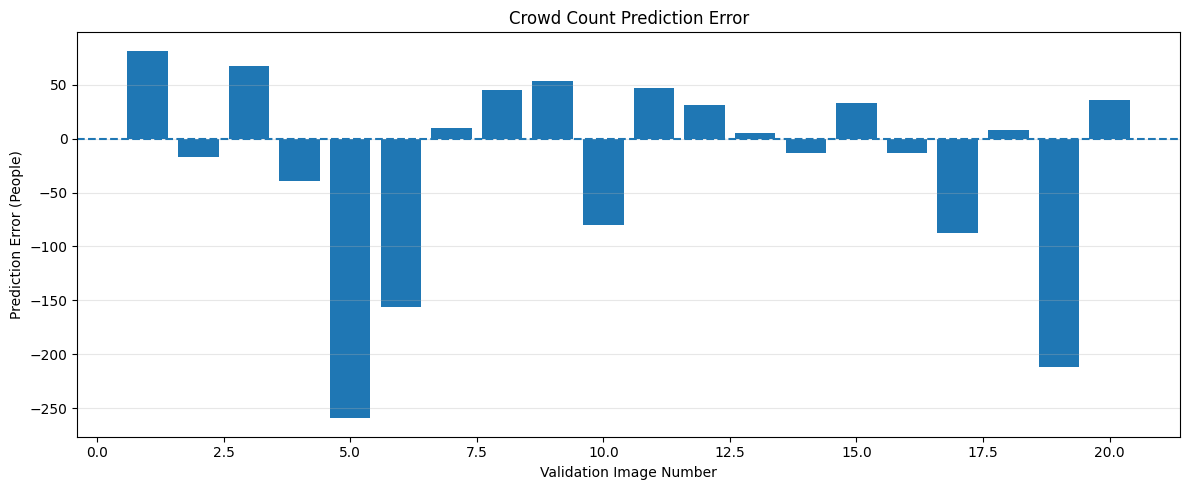

Positive error = Overestimation
Negative error = Underestimation


In [108]:
# Output 3: Visualize the crowd-counting error

errors = predicted - actual

plt.figure(figsize=(12, 5))

plt.bar(image_numbers, errors)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Validation Image Number")
plt.ylabel("Prediction Error (People)")
plt.title("Crowd Count Prediction Error")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Positive error = Overestimation")
print("Negative error = Underestimation")


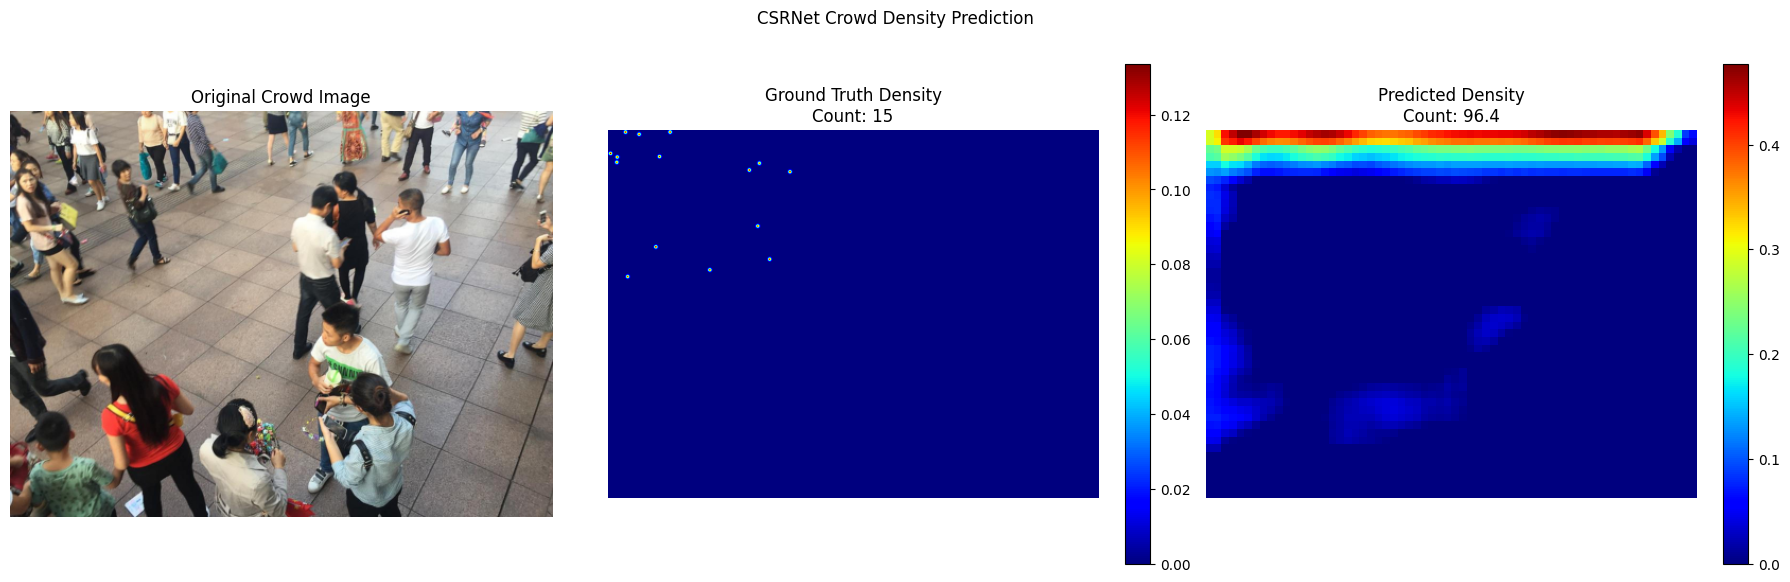

Actual crowd count: 15
Predicted crowd count: 96.43
Absolute error: 81.43


In [109]:
# Final Output 4: Display a crowd image with its density map

import torch
import matplotlib.pyplot as plt
import numpy as np

model.eval()

# Get one validation image
images, density_maps = next(iter(val_loader))
images = images.to(device)

with torch.no_grad():
    output = model(images)

image = images[0].cpu().permute(1, 2, 0).numpy()
predicted_density = output[0, 0].cpu().numpy()
actual_density = density_maps[0, 0].cpu().numpy()

actual_count = actual_density.sum()
predicted_count = predicted_density.sum()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image)
axes[0].set_title("Original Crowd Image")
axes[0].axis("off")

im1 = axes[1].imshow(
    actual_density, cmap="jet"
)
axes[1].set_title(
    f"Ground Truth Density\nCount: {actual_count:.0f}"
)
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(
    predicted_density, cmap="jet"
)
axes[2].set_title(
    f"Predicted Density\nCount: {predicted_count:.1f}"
)
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.suptitle("CSRNet Crowd Density Prediction")
plt.tight_layout()
plt.show()

print(f"Actual crowd count: {actual_count:.0f}")
print(f"Predicted crowd count: {predicted_count:.2f}")
print(f"Absolute error: {abs(predicted_count - actual_count):.2f}")


In [110]:
# Save the validation results

final_results = pd.DataFrame({
    "Image_Number": np.arange(1, len(actual) + 1),
    "Actual_Count": actual,
    "Predicted_Count": predicted,
    "Absolute_Error": np.abs(predicted - actual)
})

final_results.to_csv(
    "event_crowd_analysis_results.csv",
    index=False
)

print("Validation results saved successfully.")
print(final_results.head(10))


Validation results saved successfully.
   Image_Number  Actual_Count  Predicted_Count  Absolute_Error
0             1     15.000000        96.429420       81.429420
1             2    142.000000       125.367226       16.632774
2             3     42.000000       109.534828       67.534828
3             4    172.999969       133.340027       39.659943
4             5    378.000122       118.705482      259.294640
5             6    281.000061       124.576111      156.423950
6             7     95.999962       105.449158        9.449196
7             8     61.000000       105.564217       44.564217
8             9     45.000008        97.939964       52.939957
9            10    178.000000        98.132164       79.867836


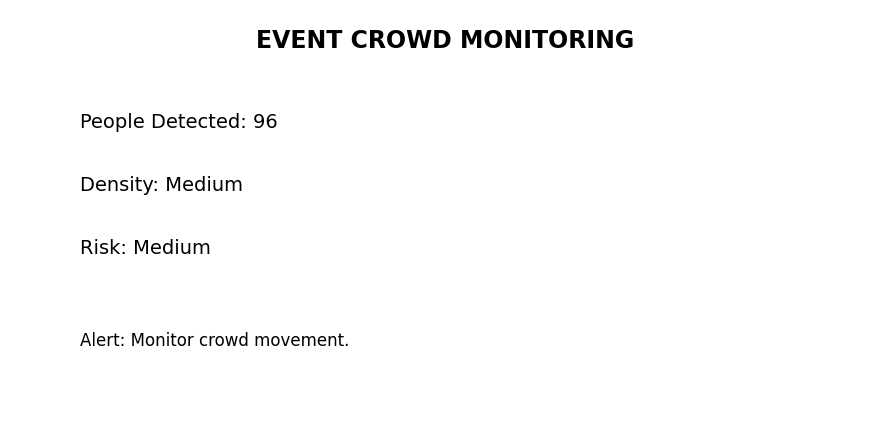

Note: Crowd count and risk are estimates.
The model needs validation before real-world safety use.


In [111]:

import torch
import matplotlib.pyplot as plt
import numpy as np

# Use the existing trained model
model.eval()

# Get one validation image
images, density_maps = next(iter(val_loader))
images = images.to(device)

with torch.no_grad():
    output = model(images)

# Count people from the predicted density map
predicted_count = max(0, float(output[0, 0].sum().item()))

# Simple illustrative thresholds.
# Adjust these thresholds for your actual venue and capacity.
if predicted_count < 50:
    density_level = "Low"
    risk_level = "Low"
    alert = "Crowd levels are normal."
elif predicted_count < 150:
    density_level = "Medium"
    risk_level = "Medium"
    alert = "Monitor crowd movement."
else:
    density_level = "High"
    risk_level = "Medium"
    alert = "Crowded area. Monitor and assess."

# Display the dashboard in Jupyter
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axis("off")

ax.text(
    0.5, 0.91, "EVENT CROWD MONITORING",
    ha="center", fontsize=17, fontweight="bold"
)

ax.text(
    0.08, 0.72, f"People Detected: {predicted_count:.0f}",
    fontsize=14
)
ax.text(
    0.08, 0.57, f"Density: {density_level}",
    fontsize=14
)
ax.text(
    0.08, 0.42, f"Risk: {risk_level}",
    fontsize=14
)
ax.text(
    0.08, 0.20, f"Alert: {alert}",
    fontsize=12, wrap=True
)

plt.tight_layout()
plt.show()

print("Note: Crowd count and risk are estimates.")
print("The model needs validation before real-world safety use.")
